# RSNA Knee: первый бейзлайн (локальная версия)

## Что это

Первая версия пайплайна, написанная до разбора данных: **одна картинка на колено** (3 среза из середины
сагиттальной серии), энкодер DINOv2 ViT-B, лосс BCE, 5 фолдов. Ноутбук оставлен как точка отсчёта:
с ним сравнивается вторая версия (`02_report_labels_mil.ipynb`).

Картинки берутся из локального «сырого» кэша, как в 02: `data/raw/studies/<ID>.npz`, по файлу на колено,
внутри все срезы выбранных серий по порядку. Логика обучения, модель и обработка меток не менялись.

**Что нужно:** `data/raw/` (кэш из `03_build_cache_kaggle.ipynb`) и веса `weights/vit_base_patch14_dinov2.pth`.

## Почему эта версия даёт AUC около 0.5-0.6

| Проблема | Где в коде | Что происходит | Как в 02 |
|---|---|---|---|
| **пустые метки стали нулями** | `np.nan_to_num(labels, nan=0.0)` в `RSNAKneeDataset` | у 4349 из 4407 колен в `train.csv` метки пустые (NaN). Ноль = «здоров по всем 12 находкам». Модель учится говорить «здоров» всегда | метки читаются из текстов заключений |
| **одна картинка на колено** | `load_three_slices` | 3 среза из середины одной серии. Разрыв мениска сбоку или выпот на другой проекции модель не видит | до 6 серий × 4 окна = 24 картинки |
| **валидация на шуме** | `validate_one_epoch` | позитивы есть только у ~12 размеченных колен в фолде, AUC считается почти по ним одним | отдельная метрика на 58 размеченных + метрика по текстам |
| **загрузка весов без проверки** | `load_state_dict(..., strict=False)` | если ключи не совпали, ошибки не будет, сеть тихо начнёт со случайных весов | `strict=False` + проверка, что совпали все ключи |
| **нет нормализации ImageNet** | `/ 255.0` | DINOv2 учили на картинках с вычтенным средним и делением на std | нормализация в `Dataset` |

## Порядок ячеек

1. Импорты, устройство, сид и константы.
2. Пути и список целей.
3. Данные: как из файла колена берутся 3 среза.
4. `Dataset`, модель, шаг обучения и шаг проверки.
5. Обучение 5 фолдов и разбор результатов.

### Imports

| Импорт | Зачем |
|---|---|
| `os`, `random`, `copy`, `warnings`, `Path` | служебное: пути, случайность, копии объектов, тишина в выводе |
| `pandas`, `numpy` | таблицы и массивы |
| `roc_auc_score`, `GroupKFold` | метрика соревнования и деление на фолды |
| `matplotlib`, `tqdm`, `torchinfo` | картинки, полоски прогресса, сводка модели (последние две здесь не используются) |
| `timm` | библиотека готовых моделей; отсюда DINOv2 |
| `torch`, `nn`, `DataLoader`, `Dataset`, `F` | PyTorch: тензоры, слои, загрузка данных |
| `torchvision.transforms` | аугментации картинок (здесь не используются) |

In [15]:
import os                                               # работа с ОС: пути, переменные окружения, список файлов
import warnings                                         # управление предупреждениями библиотек
import random                                           # случайные числа стандартной библиотеки Python
import copy                                             # копирование объектов (здесь не используется)
from pathlib import Path                                # пути: Path("a") / "b" склеивает части пути

import pandas as pd                                     # таблицы (DataFrame): чтение csv, фильтры, группировки
import numpy as np                                      # массивы чисел и математика над ними

import sklearn                                          # scikit-learn: классическое ML, отсюда метрики и фолды
from sklearn.metrics import roc_auc_score          # метрика соревнования: площадь под ROC-кривой
from sklearn.model_selection import GroupKFold     # деление на фолды так, чтобы группа не попала в оба

import matplotlib.pyplot as plt                         # рисование картинок и графиков
from tqdm.auto import tqdm                              # полоска прогресса для циклов (здесь не используется)
from torchinfo import summary                           # сводка слоёв модели (здесь не используется)

import timm                                        # готовые модели, в том числе DINOv2

import torch                                            # PyTorch: тензоры, видеокарта, обучение
from torch import nn                                    # nn - слои нейросетей (Linear, Conv2d) и базовый класс nn.Module
from torch .utils.data import DataLoader, Dataset  # Dataset - «как достать пример i», DataLoader - «собери батч»
import torch.nn.functional as F                         # функции без весов: активации, лоссы
from torchvision import transforms                      # аугментации картинок (здесь не используются)
from torchvision.transforms import v2                   # новая версия аугментаций (здесь не используется)


warnings.filterwarnings("ignore")                       # не печатать предупреждения библиотек
print("All imported.")                                  # сигнал, что все импорты прошли без ошибок

All imported.


### Устройство

Где считать: `mps` - видеокарта Apple Silicon, `cuda` - видеокарта NVIDIA (Kaggle, Colab), иначе процессор.
Проверки идут по порядку: первая подошедшая побеждает.

In [16]:
# Выражение «A if условие else B if условие2 else C» читается слева направо:
# есть MPS -> "mps"; иначе есть CUDA -> "cuda"; иначе "cpu"
device = torch.device("mps"
if torch.backends.mps.is_available()
else "cuda"
if torch.cuda.is_available()
else "cpu")

print(f"Device: '{device}'")                            # какое устройство выбрано

Device: 'mps'


### Константы и сид

| Константа | Значение | Что значит |
|---|---|---|
| `SEED` | 2026 | зерно случайности: одинаковое зерно = одинаковые случайные числа при каждом запуске |
| `N_SPLITS` | 5 | на сколько фолдов делим данные: учим 5 моделей, каждая проверяется на своей 1/5 |
| `BATCH_SIZE` | 8 | сколько картинок в одном шаге обучения |
| `NUM_EPOCHS` | 10 | сколько раз модель проходит все обучающие данные |
| `LR` | 2e-5 | шаг обучения (здесь не используется: в цикле обучения стоит `lr=1e-5`) |

`seed_everything` задаёт зерно всем генераторам сразу: Python, NumPy, PyTorch (CPU, CUDA, MPS).
`cudnn.deterministic` и `benchmark=False` делают расчёты на CUDA повторяемыми (чуть медленнее).

In [17]:
SEED = 2026                                             # зерно случайности
N_SPLITS = 5                                            # фолдов в GroupKFold
BATCH_SIZE = 8                                          # картинок в батче
NUM_EPOCHS = 10                                         # эпох на фолд
LR = 2e-5                                               # шаг обучения (в цикле ниже стоит свой lr=1e-5, эта константа не используется)

def seed_everything(seed=42):                           # seed=42 - значение по умолчанию, если зерно не передали
    random.seed(seed)                      # random из стандартной библиотеки
    torch.manual_seed(seed)                # PyTorch на CPU
    torch.cuda.manual_seed(seed)           # PyTorch на CUDA (если её нет - ничего не делает)
    if torch.backends.mps.is_available():               # есть видеокарта Apple
        torch.mps.manual_seed(seed)        # PyTorch на MPS
    np.random.seed(seed)                   # NumPy
    torch.backends.cudnn.deterministic=(True)           # CUDA: одинаковые результаты при одинаковом зерне
    torch.backends.cudnn.benchmark=(False)              # CUDA: не подбирать самый быстрый алгоритм (он может быть неповторяемым)
    os.environ["PYTHONHASHSEED"] = str(seed)            # зерно хэширования Python (порядок в set/dict)

seed_everything(SEED)                                   # применить зерно
print(f"General seed: {SEED}")                          # напечатать, какое зерно

General seed: 2026


### Пути

Ноутбук запускается из папки `rsna-knee-abnormality-detection`, поэтому пути относительные.
`assert p.exists()` сразу останавливает ноутбук с понятной ошибкой, если чего-то нет, вместо странной ошибки потом.

In [18]:
# Ноутбук запускается из папки rsna-knee-abnormality-detection
DATA_DIR = Path("data") / "raw"            # studies/ + train.csv
STUDY_DIR = DATA_DIR / "studies"           # по файлу на исследование: {"slot0": [n_срезов, 224, 224], ...}
WEIGHTS_PATH = Path("weights") / "vit_base_patch14_dinov2.pth"   # предобученные веса DINOv2 ViT-B
OUT_DIR = Path("outputs") / "baseline"     # сюда пишутся лучшие веса каждого фолда
OUT_DIR.mkdir(parents=True, exist_ok=True)              # создать папку; parents - и родительские; exist_ok - не падать, если есть

for p in (STUDY_DIR, DATA_DIR / "train.csv", WEIGHTS_PATH):  # проверяем три пути
    assert p.exists(), f"нет {p}"                       # assert условие, сообщение: остановиться с ошибкой, если условие ложно

### Цели

12 колонок `train.csv`, которые надо предсказать. Порядок важен: в нём же идут выходы модели и колонки сабмита.

| Цель | Что это |
|---|---|
| ACL / MCL | разрыв передней крестообразной / медиальной коллатеральной связки |
| Medial / Lateral Meniscus | разрыв внутреннего / наружного мениска |
| Medial / Lateral / PF OA | артроз внутреннего / наружного / пателлофеморального (за коленной чашечкой) отдела |
| Effusion | выпот: лишняя жидкость в суставе |
| Synovitis | воспаление синовиальной оболочки |
| Baker's | киста Бейкера: мешочек с жидкостью под коленом сзади |
| Contusion | ушиб кости (отёк костного мозга после травмы) |
| Fracture | перелом |

In [19]:
TARGET_COLS = [                                         # 12 колонок-целей в порядке train.csv
    'ACL', 'MCL', 'Medial Meniscus', 'Lateral Meniscus',
    'Medial OA', 'Lateral OA', 'PF OA', 'Effusion',
    'Synovitis', "Baker's", 'Contusion', 'Fracture'
]

Что лежит в `data/raw/`: 4407 файлов колен в `studies/` и файлы-справки от билдера.

In [20]:
print(f"studies/: {len(list(STUDY_DIR.glob('*.npz')))} файлов")  # glob('*.npz') - все файлы с таким окончанием
for p in sorted(DATA_DIR.iterdir()):                    # iterdir - всё содержимое папки; sorted - по алфавиту
    if p.is_file():                                     # только файлы, папки (studies) пропускаем
        # st_size - размер в байтах; / 1024 ** 2 - в мегабайтах
        print(f"{p.name:<20} {p.stat().st_size / 1024 ** 2:>10.1f} МБ")

studies/: 4407 файлов
index_part0.csv             1.6 МБ
index_part1.csv             1.6 МБ
rsna_raw_meta.json          0.0 МБ
train.csv                   5.4 МБ


### Data

Бейзлайн берёт из каждого колена **одну картинку из 3 каналов**:

1. открывает `studies/<ID>.npz`;
2. выбирает серию: `slot0` (сбоку, с подавлением жира), если её нет - `slot3` (сбоку, без), если нет и её - первую,
   какая есть;
3. берёт центральный срез стопки `c = n // 2` и два среза на `STEP = 4` дальше в обе стороны: `[c-4, c, c+4]`;
4. эти 3 среза становятся 3 каналами картинки (как R, G и B у цветной фотографии).

Пример: в серии 22 среза -> `c = 11` -> срезы `[7, 11, 15]` -> массив `[3, 224, 224]`.

`np.clip(..., 0, n - 1)` не даёт выйти за край стопки, если срезов мало.

In [21]:
train_df = pd.read_csv(DATA_DIR / "train.csv")     # одна строка = одно колено
study_ids = train_df["StudyInstanceUID"].astype(str).tolist()  # колонка ID -> список строк

# Какую картинку берёт бейзлайн: одна серия и три её среза вокруг центра стека.
# Слоты в файле: slot0 SAG_FS, slot1 COR_FS, slot2 AX_FS, slot3 SAG_NOFS, slot4 COR_NOFS, slot5 AX_NOFS.
SLOT_ORDER = ["slot0", "slot3"]   # сагиттальная с подавлением жира; если её нет - сагиттальная без него
STEP = 4                          # как в первой версии: центральный срез и два среза на 4 дальше в обе стороны


def load_three_slices(study_id):
    """[3, H, W] uint8: срезы c-STEP, c, c+STEP из сагиттальной серии исследования (c - центр стека)."""
    with np.load(STUDY_DIR / f"{study_id}.npz") as z:        # z.files = ["slot0", "slot1", ...]
        # next(...): первый ключ из SLOT_ORDER, который есть в файле; если ни одного - первый ключ по алфавиту
        key = next((k for k in SLOT_ORDER if k in z.files), sorted(z.files)[0])
        stack = z[key]                                        # [n_срезов, H, W], по порядку в теле
    c = len(stack) // 2                                       # центр стопки
    idx = np.clip([c - STEP, c, c + STEP], 0, len(stack) - 1) # номера трёх срезов, не выходя за края
    return stack[idx]                                         # [3, 224, 224]

Проверка глазами: случайное колено, его 3 среза по отдельности. Тип `uint8` значит яркость 0..255.

Shape image: (3, 224, 224)
Type data image: uint8


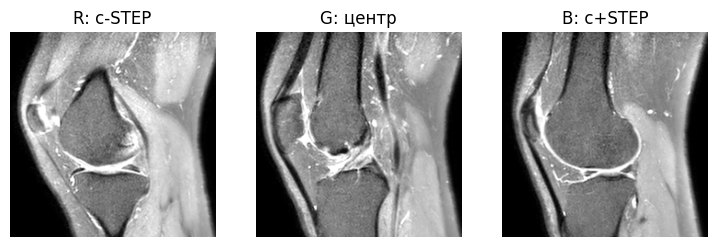

In [22]:
study = random.choice(study_ids)                        # случайное колено
image = load_three_slices(study)   # [3, 224, 224]: три среза -> три канала

print(f"Shape image: {image.shape}")                    # форма массива: (3, 224, 224)
print(f"Type data image: {image.dtype}")                # тип: uint8 (целые 0..255)

fig, axes = plt.subplots(1, 3, figsize=(9, 3))          # 1 строка, 3 картинки; figsize - размер в дюймах
for ax, ch, name in zip(axes, image, ["R: c-STEP", "G: центр", "B: c+STEP"]):  # zip: ось, канал и подпись парами
    ax.imshow(ch, cmap="gray"); ax.set_title(name); ax.axis("off")  # показать канал серым, подписать, убрать оси
plt.show()                                              # показать картинку

### Custom Dataset

`Dataset` в PyTorch - это класс с тремя методами:

| Метод | Когда вызывается | Что делает здесь |
|---|---|---|
| `__init__` | один раз при создании | запоминает таблицу колен и силу сглаживания меток |
| `__len__` | `DataLoader` спрашивает, сколько примеров | число строк таблицы |
| `__getitem__(idx)` | для каждого примера в батче | открывает файл колена, берёт 3 среза, делит на 255, достаёт 12 меток |

**Сглаживание меток** (`label_smoothing`): `y * (1 - s) + 0.5 * s`. При `s = 0.05` метка 1 становится 0.975,
а 0 становится 0.025: модель не тянется к крайним уверенностям. По умолчанию в классе стоит `0.5`, это очень
сильно (1 -> 0.75, 0 -> 0.25), но при создании передаётся `0.05` для обучения и `0.0` для проверки.

**Главная ошибка версии**: `np.nan_to_num(labels, nan=0.0)` превращает пустые метки в 0.

In [23]:
class RSNAKneeDataset(Dataset):
    """Одна картинка на исследование: три среза сагиттальной серии вокруг центра стека.

    __getitem__ сам открывает файл исследования, берёт три среза (load_three_slices) и делит на 255.
    Обработка меток не менялась (вместе с проблемой NaN -> 0).
    """

    def __init__(self, df, label_smoothing=0.5):        # вызывается один раз при создании датасета
        self.df = df.reset_index(drop=True)          # индексы 0..N-1, чтобы iloc[idx] совпадал с idx
        self.label_smoothing = label_smoothing          # запомнить силу сглаживания меток

    def __len__(self):                                  # DataLoader спрашивает число примеров
        return len(self.df)                             # число строк таблицы

    def __getitem__(self, idx):                         # DataLoader просит пример номер idx
        row = self.df.iloc[idx]                      # строка таблицы = одно колено
        image = load_three_slices(str(row["StudyInstanceUID"])).astype(np.float32) / 255.0   # 0..255 -> 0..1
        image = torch.tensor(image, dtype=torch.float32)          # [3, 224, 224]

        labels = row[TARGET_COLS].values.astype(np.float32)       # 12 чисел; у 98.7% колен это 12 NaN
        labels = np.nan_to_num(labels, nan=0.0)                   # ОШИБКА версии: NaN -> 0 = «здоров»
        labels = torch.tensor(labels, dtype=torch.float32)  # numpy -> тензор PyTorch

        if self.label_smoothing > 0:                    # сглаживание включено
            labels = labels * (1.0 - self.label_smoothing) + 0.5 * self.label_smoothing  # 1 -> 1 - s/2, 0 -> s/2
        return image, labels                            # пара (картинка [3,224,224], метки [12])

### Model

Две ячейки ниже - старые варианты (EfficientNet-B0 и ConvNeXt-Small), закомментированы. Используется третья:
`RSNA_dinov2`.

**`RSNA_dinov2`**: DINOv2 ViT-B из `timm` с головой на 12 выходов.

| Параметр `create_model` | Что значит |
|---|---|
| `model_name` | `vit_base_patch14_dinov2.lvd142m`: ViT-Base (86M параметров), патчи 14×14, обучен методом DINOv2 на 142M картинок |
| `pretrained=False` | не скачивать веса из интернета: они грузятся из файла ниже |
| `num_classes=12` | новая голова: линейный слой 768 -> 12 логитов |
| `dynamic_img_size=True` | разрешить вход любого размера (веса сохранены под 518 px, у нас 224) |

Из файла весов удаляются ключи `head`/`classifier` (старая голова не подходит), остальное грузится с
`strict=False`. Минус: если имена ключей не совпадут, ошибки не будет, и сеть молча останется со случайными весами.

In [24]:
# class RSNA_efficientnet_b0(nn.Module):
#   def __init__(self, model_name="efficientnet_b0", pretrained=False):
#     super().__init__()

#     self.model = timm.create_model(
#         model_name, pretrained=pretrained, num_classes=len(TARGET_COLS)
#     )

#     weights_path = (
#         "/kaggle/input/datasets/tihon2010/weights-efficientnet-b0/efficientnet_b0.pth"
#     )
#     if os.path.exists(weights_path):
#       print("Download weights ...")
#       state_dict = torch.load(weights_path, map_location="cpu")

#       if "classifier.weight" in state_dict:
#         del state_dict["classifier.weight"]
#       if "classifier.bias" in state_dict:
#         del state_dict["classifier.bias"]

#       self.model.load_state_dict(state_dict, strict=False)
#     else:
#       print("Weights not found path:", weights_path)

#   def forward(self, x):
#     return self.model(x)

In [25]:
# class RSNA_convnext_small(nn.Module):
#   def __init__(self, model_name="convnext_small", pretrained=False):
#     super().__init__()

#     self.model = timm.create_model(
#         model_name, pretrained=pretrained, num_classes=len(TARGET_COLS)
#     )

#     weights_path = (
#         "/kaggle/input/datasets/tihon2010/weights-convnext-small/convnext_small.pth"
#     )
#     if os.path.exists(weights_path):
#       print("Download weights ...")
#       state_dict = torch.load(weights_path, map_location="cpu")

#       for key in list(state_dict.keys()):
#           if "head" in key or "classifier" in key:
#               del state_dict[key]

#       self.model.load_state_dict(state_dict, strict=False)
#     else:
#       print("Weights not found path:", weights_path)

#   def forward(self, x):
#     return self.model(x)

In [26]:
class RSNA_dinov2(nn.Module):
    def __init__(self, model_name="vit_base_patch14_dinov2.lvd142m", pretrained=False):  # слои модели создаются здесь
        super().__init__()                              # обязательная инициализация nn.Module

        # архитектура ViT-B с новой головой на 12 выходов; dynamic_img_size - принимает 224 вместо 518
        self.model = timm.create_model(
            model_name, pretrained=pretrained, num_classes=len(TARGET_COLS), dynamic_img_size=True
        )

        weights_path = WEIGHTS_PATH                     # путь к файлу весов из настроек
        if os.path.exists(weights_path):                # файл весов есть
            print("Download weights ...")               # на самом деле загрузка с диска, не из интернета
            state_dict = torch.load(weights_path, map_location="cpu")   # {имя слоя: тензор весов}

            # старая голова не подходит к нашей (у нас 12 выходов) - удаляем её ключи
            for key in list(state_dict.keys()):
                if "head" in key or "classifier" in key:  # ключ относится к старой голове
                    del state_dict[key]                 # удалить его из словаря

            # strict=False: несовпавшие ключи молча пропускаются (лучше проверять, что вернулось)
            self.model.load_state_dict(state_dict, strict=False)
        else:                                           # иначе
            print("Weights not found path:", weights_path)  # предупредить: сеть останется со случайными весами

    def forward(self, x):
        # x [batch, 3, 224, 224] -> логиты [batch, 12] (до сигмоиды)
        return self.model(x)

### Train step

Одна эпоха обучения - классические 5 строк PyTorch для каждого батча:

| Строка | Что делает |
|---|---|
| `model.train()` | режим обучения: включает Dropout |
| `outputs = model(images)` | прямой проход: картинки -> логиты `[8, 12]` |
| `loss = criterion(outputs, labels)` | `BCEWithLogitsLoss`: сигмоида + бинарная кросс-энтропия по 12 целям |
| `optimizer.zero_grad()` | обнулить градиенты прошлого шага (иначе они складываются) |
| `loss.backward()` | посчитать градиенты: в какую сторону менять каждый вес |
| `optimizer.step()` | сдвинуть веса на шаг против градиента |

Возвращает средний лосс за эпоху.

In [27]:
def train_one_epoch(model, dataloader, optimizer, criterion, device):  # одна эпоха обучения, возвращает средний лосс

    model.train()                                       # режим обучения: Dropout включён
    running_loss = 0.0                                  # сумма лоссов за эпоху

    for images, labels in dataloader:       # images [8, 3, 224, 224], labels [8, 12]
        images = images.to(device)          # перенести на видеокарту
        labels = labels.to(device)                      # метки на то же устройство

        outputs = model(images)             # логиты [8, 12]
        loss = criterion(outputs, labels)   # одно число: средняя ошибка по батчу и 12 целям

        optimizer.zero_grad()                           # обнулить градиенты прошлого шага
        loss.backward()                                 # посчитать градиенты: куда двигать каждый вес
        optimizer.step()                                # сдвинуть веса на один шаг

        running_loss += loss.item()         # .item() - тензор из одного числа -> обычное число Python

    return running_loss / len(dataloader)   # len(dataloader) = число батчей

### Valid step

Проверка после каждой эпохи:

1. `model.eval()` и `torch.no_grad()`: без Dropout и без градиентов (быстрее и меньше памяти);
2. собираем вероятности (`sigmoid` от логитов) и метки по всем батчам;
3. **macro-AUC**: AUC отдельно по каждой из 12 целей, потом среднее. Цель пропускается, если в валидации у неё
   только один класс (все 0): AUC тогда не определён.

**Почему этот AUC шумный.** Из-за NaN -> 0 «единицы» есть только у размеченных колен, а их в фолде ~12 из ~880.
По многим целям позитивов 2-5 штук, и AUC по ним прыгает от эпохи к эпохе.

In [28]:
def validate_one_epoch(model, dataloader, criterion, device):  # проверка: лосс и macro-AUC на валидации

    model.eval()                                        # режим проверки: Dropout выключен
    running_loss = 0.0                                  # сумма лоссов за эпоху
    all_preds = []                                      # сюда складываем предсказания батчей
    all_labels = []                                     # сюда метки батчей

    with torch.no_grad():                               # без градиентов: быстрее и меньше памяти
        for images, labels in dataloader:               # по батчам: картинки и метки
            images = images.to(device)                  # картинки на видеокарту
            labels = labels.to(device)                  # метки на то же устройство

            outputs = model(images)                     # логиты [батч, 12]
            loss = criterion(outputs, labels)           # лосс батча

            running_loss += loss.item()                 # копим лосс; .item() - тензор из одного числа -> число Python

            preds = torch.sigmoid(outputs).cpu().numpy()     # логиты -> вероятности 0..1
            all_preds.append(preds)                     # сохранить вероятности батча
            all_labels.append(labels.cpu().numpy())     # .cpu() - с видеокарты в память; .numpy() - в массив numpy

    val_loss = running_loss / len(dataloader)           # средний лосс по батчам
    all_preds = np.concatenate(all_preds, axis=0)            # [N_val, 12]
    all_labels = np.concatenate(all_labels, axis=0)          # [N_val, 12]

    class_aucs = []                                     # AUC по каждой цели
    for i in range(all_labels.shape[1]):                     # по 12 целям
        if len(np.unique(all_labels[:, i])) > 1:             # нужны и 0, и 1
            try:                                        # попробовать; ошибку перехватит except
                score = roc_auc_score(all_labels[:, i], all_preds[:, i])  # AUC цели i: [:, i] - колонка i всех строк
                if not np.isnan(score):                 # NaN - «не число», такую цель пропускаем
                    class_aucs.append(score)            # сохранить AUC цели
            except Exception:                           # любая ошибка внутри try
                pass                                    # ничего не делать

    macro_auc = np.mean(class_aucs) if class_aucs else 0.0   # среднее по целям = метрика соревнования

    return val_loss, macro_auc                          # два значения сразу (кортеж)

### Train and Eval

Первая ячейка - старый цикл на одном фолде, закомментирован. Работает вторая.

**Фолды.** `GroupKFold(n_splits=5)` делит колена на 5 групп по `StudyInstanceUID`. Каждое колено - своя группа,
так что одно колено не попадёт и в обучение, и в проверку. Номер фолда пишется в колонку `fold`.

**Для каждого фолда:**
1. `Subset` берёт из полного датасета строки этого фолда (обучение: со сглаживанием 0.05, проверка: без);
2. `DataLoader` с `num_workers=0`: данные готовит сам ноутбук. Класс объявлен в ячейке, а воркеры на macOS
   его не видят (в 02 для этого класс вынесен в файл);
3. новая модель; **размораживаются только голова и последние 2 блока ViT (`blocks.10`, `blocks.11`)** из 12;
4. `AdamW(lr=1e-5, weight_decay=1e-2)` по обучаемым параметрам, `CosineAnnealingLR`: LR плавно падает до 0 за 10 эпох;
5. 10 эпох; веса сохраняются, когда val AUC лучше прежнего.

In [29]:
# train_df = pd.read_csv(os.path.join(DATA_DIR, "train.csv"))

# gkf = GroupKFold(n_splits=N_SPLITS)
# train_df["fold"] = -1

# for fold, (train_idx, val_idx) in enumerate(gkf.split(train_df, groups=train_df["StudyInstanceUID"])):
#     train_df.loc[val_idx, "fold"] = fold

# df_train = train_df[train_df["fold"] != 0].reset_index(drop=True)
# df_val = train_df[train_df["fold"] == 0].reset_index(drop=True)
# print(f"Train patients: {len(df_train)}, Val patients: {len(df_val)}")

# train_dataset = RSNAKneeDataset(df_train, img_size=224, is_train=True)
# val_dataset = RSNAKneeDataset(df_val, img_size=224, is_train=True)

# train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=0)
# val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)

# model = RSNAKneeModel(model_name="efficientnet_b0", pretrained=False).to(device)
# optimizer = torch.optim.AdamW(model.parameters(), lr=LR)
# criterion = nn.BCEWithLogitsLoss()
# scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=NUM_EPOCHS)

# best_val_auc = 0.0

# print(f"Start train model ...")
# for epoch in range(NUM_EPOCHS):
#     train_loss = train_one_epoch(model, train_loader, optimizer, criterion, device)
#     val_loss, val_auc = validate_one_epoch(model, val_loader, criterion, device)

#     scheduler.step()

#     print(f"Epoch {epoch+1}/{NUM_EPOCHS} | Train Loss: {train_loss:.4f} | Val Loss: {val_loss:.4f} | Val Macro-AUC: {val_auc:.4f}")

#     if val_auc > best_val_auc:
#         best_val_auc = val_auc
#         torch.save(model.state_dict(), "best_rsna_model.pth")
#         print("Saved new best model (best_rsna_model.pth)")

# print("Train finish.")

In [30]:
gkf = GroupKFold(n_splits=N_SPLITS)                     # делитель на 5 фолдов по группам
train_df["fold"] = -1                                   # новая колонка; -1 = фолд ещё не назначен

# gkf.split отдаёт пары (индексы обучения, индексы проверки) для каждого из 5 фолдов
for fold, (train_idx, val_idx) in enumerate(gkf.split(train_df, groups=train_df["StudyInstanceUID"])):
    train_df.loc[val_idx, "fold"] = fold                # .loc[строки, колонка] = значение: этим строкам номер фолда

full_train_dataset = RSNAKneeDataset(train_df, label_smoothing=0.05)  # датасет обучения: метки сглажены на 5%
full_val_dataset = RSNAKneeDataset(train_df, label_smoothing=0.0)  # датасет проверки: метки без сглаживания

best_auc_score = []                                     # лучший AUC каждого фолда

print(f"\n=== Starting {N_SPLITS}-Fold Training ===")   # \n - перевод строки
for fold in range(N_SPLITS):                            # fold = 0, 1, 2, 3, 4
    print(f"\n--- Fold {fold+1} ---")                   # фолды печатаются с 1

    train_idx = train_df[train_df["fold"] != fold].index.tolist()   # 4/5 колен
    val_idx = train_df[train_df["fold"] == fold].index.tolist()     # 1/5 колен

    train_dataset = torch.utils.data.Subset(full_train_dataset, train_idx)  # Subset - датасет только из строк train_idx
    val_dataset = torch.utils.data.Subset(full_val_dataset, val_idx)  # то же для проверки

    # num_workers=0: класс объявлен в ноутбуке, а воркеры на macOS его не видят (в 02 класс вынесен в файл)
    train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=0)
    val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)  # проверка без перемешивания

    model = RSNA_dinov2("vit_base_patch14_dinov2.lvd142m", pretrained=False).to(device)  # новая модель на видеокарте

    # заморозить всё, кроме головы и двух последних блоков ViT (blocks.10 и blocks.11)
    for name, param in model.named_parameters():
        param.requires_grad = False                     # заморозить параметр
        if "head" in name or "blocks.10." in name or "blocks.11." in name:  # голова и два последних блока
            param.requires_grad = True                  # разморозить: эти веса учатся

    optimizer = torch.optim.AdamW(                      # оптимизатор AdamW: Adam + weight decay
        filter(lambda p: p.requires_grad, model.parameters()),   # только обучаемые параметры
        lr=1e-5,
        weight_decay=1e-2
    )

    criterion = torch.nn.BCEWithLogitsLoss()            # сигмоида + бинарная кросс-энтропия, среднее по 12 целям
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=NUM_EPOCHS)   # LR по косинусу до 0

    best_val_auc = 0.0                                  # лучший AUC фолда пока 0
    model_save_path = OUT_DIR / f"best_rsna_dinov2_model_fold_{fold+1}.pth"  # куда сохранять лучшие веса фолда

    for epoch in range(NUM_EPOCHS):                     # epoch = 0..9
        train_loss = train_one_epoch(model=model,       # эпоха обучения; аргументы по именам
                                     dataloader=train_loader,
                                     optimizer=optimizer,
                                     criterion=criterion,
                                     device=device
                                    )
        val_loss, val_auc = validate_one_epoch(model=model,  # проверка после эпохи
                                         dataloader=val_loader,
                                         criterion=criterion,
                                         device=device
                                         )
        scheduler.step()                    # шаг LR раз в эпоху

        print(f"Epoch {epoch+1}/{NUM_EPOCHS} | Train Loss: {train_loss:.4f} | Val Loss: {val_loss:.4f} | Val Auc: {val_auc:.4f}")  # :.4f - 4 знака после точки

        if val_auc > best_val_auc:                      # стало лучше
            best_val_auc = val_auc                      # запомнить новый рекорд
            torch.save(model.state_dict(), model_save_path)  # state_dict - словарь всех весов модели
            print(f"Saved new best model for fold {fold+1} ({model_save_path})")  # сообщить о сохранении

    best_auc_score.append(best_val_auc)                 # рекорд фолда в список

print(f"\n=== Training finished ===")                   # конец обучения
print(f'Mean Best Val Macro-AUC across all folds: {np.mean(best_auc_score):.4f}')  # среднее лучших AUC по фолдам


=== Starting 5-Fold Training ===

--- Fold 1 ---
Download weights ...
Epoch 1/10 | Train Loss: 0.1367 | Val Loss: 0.0545 | Val Auc: 0.6262
Saved new best model for fold 1 (outputs/baseline/best_rsna_dinov2_model_fold_1.pth)
Epoch 2/10 | Train Loss: 0.1312 | Val Loss: 0.0512 | Val Auc: 0.6760
Saved new best model for fold 1 (outputs/baseline/best_rsna_dinov2_model_fold_1.pth)
Epoch 3/10 | Train Loss: 0.1307 | Val Loss: 0.0467 | Val Auc: 0.6907
Saved new best model for fold 1 (outputs/baseline/best_rsna_dinov2_model_fold_1.pth)
Epoch 4/10 | Train Loss: 0.1303 | Val Loss: 0.0479 | Val Auc: 0.6871
Epoch 5/10 | Train Loss: 0.1291 | Val Loss: 0.0477 | Val Auc: 0.6665
Epoch 6/10 | Train Loss: 0.1269 | Val Loss: 0.0480 | Val Auc: 0.5102
Epoch 7/10 | Train Loss: 0.1248 | Val Loss: 0.0487 | Val Auc: 0.5493
Epoch 8/10 | Train Loss: 0.1228 | Val Loss: 0.0494 | Val Auc: 0.4578
Epoch 9/10 | Train Loss: 0.1217 | Val Loss: 0.0496 | Val Auc: 0.4912
Epoch 10/10 | Train Loss: 0.1211 | Val Loss: 0.0502 |

### Разбор результатов прогона

Что видно в логе выше:

| Наблюдение | Почему |
|---|---|
| train loss плавно падает (0.137 -> 0.121) | модель учится предсказывать нули: почти все метки = 0, это легко |
| val AUC скачет 0.46-0.69 без тренда | позитивы есть только у ~12 размеченных колен в фолде, AUC по 2-5 позитивам - лотерея |
| лосс падает, а AUC не растёт: в 4 фолдах из 5 лучшая эпоха с 3-й по 5-ю, дальше AUC проседает | модель всё сильнее уходит в «всегда здоров» |
| лучший AUC фолда 0.59-0.69, в среднем 0.637 | выбор «лучшей эпохи» по шумной метрике завышает число: честная оценка ниже |

Вывод: дело не в модели, а в метках. Во второй версии (`02_report_labels_mil.ipynb`) метки читаются из
текстов заключений, и уже первый фолд даёт **0.81** на 58 размеченных коленах.

### Predict

Предсказание test в этой версии убрано: test DICOM есть только на Kaggle, а локальный кэш содержит
только train. Сабмит для второй версии делает `04_kaggle_submission.ipynb`.